#Beyond the Sparkle
##What Really Makes Diamonds Different?

####Project Overview

Two diamonds may look nearly identical, yet their prices can be dramatically different. Is it their size, proportions, or quality that sets them apart?

In this project, we explore the hidden patterns behind diamond characteristics to discover how diamonds naturally group together. By simplifying their physical features using PCA, we investigate whether we can identify the same meaningful groups with less information.

####Research Question

Can we uncover what distinguishes different diamond groups while reducing data complexity without losing meaningful patterns?

####Our Focus

- Discover: Identify natural groups based on diamond characteristics.

- Simplify: Explore how much information can be preserved using fewer features.

- Compare: Examine whether the same groups remain recognizable after PCA.

- Interpret: Understand how the discovered groups differ in price and quality.


# Import Libraries & Load Data

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

df = pd.read_csv("/content/diamonds 2.csv")

print("Dataset Shape:", df.shape)
display(df.head())


Dataset Shape: (53940, 11)


,Unnamed: 0,carat,cut,color,clarity,depth,table,price,x,y,z
0,1,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,2,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,3,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,4,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,5,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


# Explore the Dataset

In [ ]:

print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicates (excluding row index):")
print(df.drop(columns=["Unnamed: 0"]).duplicated().sum())

print("\nStatistical Summary:")
display(df.describe().T)


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  53940 non-null  int64  
 1   carat       53940 non-null  float64
 2   cut         53940 non-null  object 
 3   color       53940 non-null  object 
 4   clarity     53940 non-null  object 
 5   depth       53940 non-null  float64
 6   table       53940 non-null  float64
 7   price       53940 non-null  int64  
 8   x           53940 non-null  float64
 9   y           53940 non-null  float64
 10  z           53940 non-null  float64
dtypes: float64(6), int64(2), object(3)
memory usage: 4.5+ MB

Missing Values:
Unnamed: 0    0
carat         0
cut           0
color         0
clarity       0
depth         0
table         0
price         0
x             0
y             0
z             0
dtype: int64

Duplicates (excluding row index):
146

Statistical Summary:


,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,53940.0,26970.500000,15571.281097,1.0,13485.75,26970.50,40455.25,53940.00
carat,53940.0,0.797940,0.474011,0.2,0.40,0.70,1.04,5.01
depth,53940.0,61.749405,1.432621,43.0,61.00,61.80,62.50,79.00
table,53940.0,57.457184,2.234491,43.0,56.00,57.00,59.00,95.00
price,53940.0,3932.799722,3989.439738,326.0,950.00,2401.00,5324.25,18823.00
x,53940.0,5.731157,1.121761,0.0,4.71,5.70,6.54,10.74
y,53940.0,5.734526,1.142135,0.0,4.72,5.71,6.54,58.90
z,53940.0,3.538734,0.705699,0.0,2.91,3.53,4.04,31.80


# Data Cleaning

In [ ]:

features = ["carat", "depth", "table", "x", "y", "z"]

# Remove unnecessary index column
df = df.drop(columns=["Unnamed: 0"])

# Check for invalid dimensions
invalid_dimensions = (df[["x", "y", "z"]] <= 0).any(axis=1)

print("Invalid dimensions:", invalid_dimensions.sum())

# Calculate expected depth percentage
calculated_depth = 200 * df["z"] / (
    df["x"] + df["y"]
).replace(0, np.nan)

# Flag major inconsistencies
depth_difference = abs(calculated_depth - df["depth"])

invalid_depth = depth_difference > 5

# Remove invalid/suspicious measurements
invalid_rows = invalid_dimensions | invalid_depth

df_clean = df.loc[~invalid_rows].copy()

print("Rows before:", len(df))
print("Rows removed:", invalid_rows.sum())
print("Rows after:", len(df_clean))


Invalid dimensions: 20
Rows before: 53940
Rows removed: 47
Rows after: 53893


# EDA Visualization

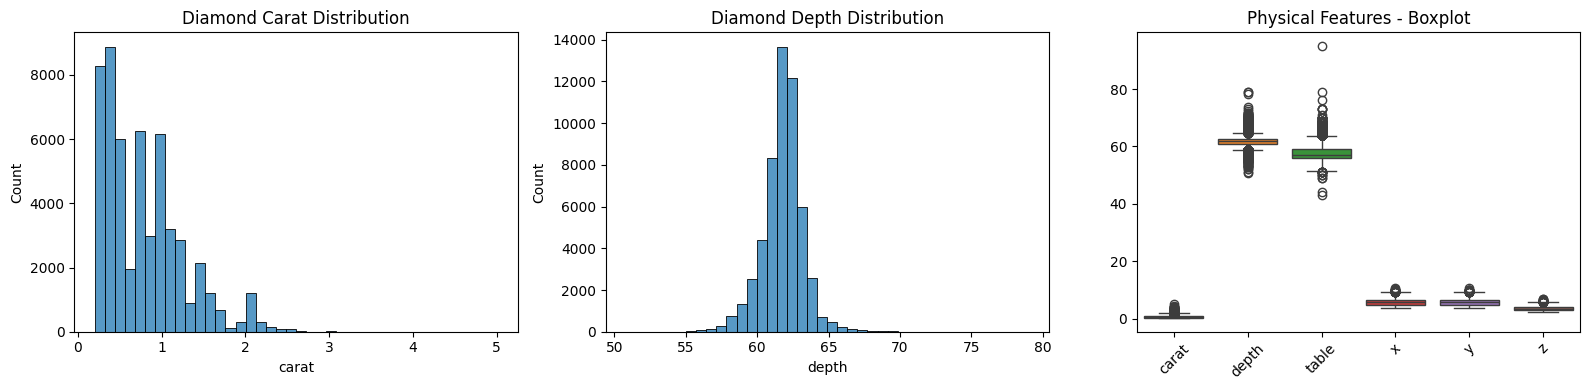

In [ ]:

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.histplot(df_clean["carat"], bins=40, ax=axes[0])
axes[0].set_title("Diamond Carat Distribution")

sns.histplot(df_clean["depth"], bins=40, ax=axes[1])
axes[1].set_title("Diamond Depth Distribution")

sns.boxplot(data=df_clean[features], ax=axes[2])
axes[2].set_title("Physical Features - Boxplot")
axes[2].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()


Diamond weight distribution.

Depth distribution.

Presence of outliers in physical features.

# Standardization

In [ ]:

scaler = StandardScaler()

X_scaled = scaler.fit_transform(df_clean[features])

X_scaled = pd.DataFrame(
    X_scaled,
    columns=features,
    index=df_clean.index
)

display(X_scaled.head())

print("Means:")
print(X_scaled.mean().round(3))

print("\nStandard Deviations:")
print(X_scaled.std(ddof=0).round(3))


,carat,depth,table,x,y,z
0,-1.198130,-0.175925,-1.099812,-1.591347,-1.577726,-1.604869
1,-1.240348,-1.368750,1.586445,-1.644946,-1.703703,-1.778459
2,-1.198130,-3.403568,3.377283,-1.502015,-1.496741,-1.778459
3,-1.071475,0.455570,0.243316,-1.368017,-1.352768,-1.315552
4,-1.029257,1.087066,0.243316,-1.242952,-1.244788,-1.141961


Means:
carat   -0.0
depth   -0.0
table    0.0
x        0.0
y       -0.0
z        0.0
dtype: float64

Standard Deviations:
carat    1.0
depth    1.0
table    1.0
x        1.0
y        1.0
z        1.0
dtype: float64


**Why StandardScaler?**

Because K-Means relies on distances. If one feature has much larger values than the rest, it can dominate the distance calculation.

After StandardScaler, the mean of each feature becomes close to zero, and its standard deviation becomes close to one.

# **Clustering Before PCA**

Here, we tried from 2 to 8 clusters. We used a sample of 3,000 rows to calculate the Silhouette Score for faster execution, while K-Means is trained on the entire clean dataset

# Elbow method to choose

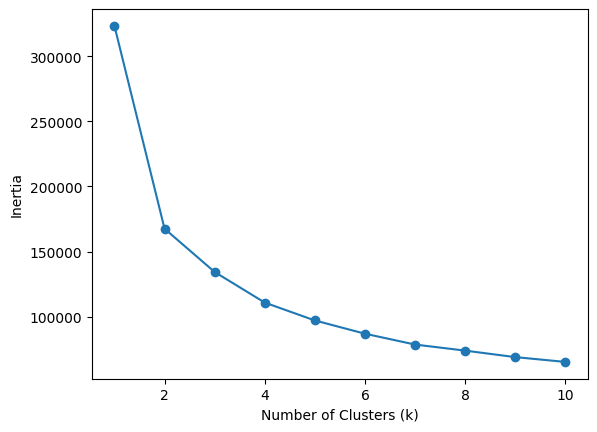

In [ ]:
inertias = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertias.append(kmeans.inertia_)

plt.plot(range(1, 11), inertias, marker='o')
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.show()

In [ ]:
# Silhouette Score to evaluate clustering quality
for k in range(2, 9):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels,sample_size=3000,random_state=42)
    print(f"K={k}: {score:.3f}")

K=2: 0.429
K=3: 0.357
K=4: 0.364
K=5: 0.295
K=6: 0.282
K=7: 0.280
K=8: 0.264


In [ ]:
#train the model with k=2 before pca
kmeans_before = KMeans(n_clusters=2, random_state=42, n_init=10)
labels_before = kmeans_before.fit_predict(X_scaled)
df_clean["cluster_before"] = labels_before
score_before = silhouette_score(X_scaled, labels_before,sample_size=3000,random_state=42)
print("Silhouette Score Before PCA:", round(score_before, 3))

Silhouette Score Before PCA: 0.429


## Apply PCA

In [ ]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
X_pca = pd.DataFrame(X_pca, columns=["PC1", "PC2"])
X_pca.head()

,PC1,PC2
0,-3.097438,0.367315
1,-2.972536,-2.329003
2,-2.563543,-5.017919
3,-2.507201,-0.030725
4,-2.284022,0.454015


In [ ]:
print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total explained variance:", pca.explained_variance_ratio_.sum())

Explained variance ratio: [0.66682508 0.21439554]
Total explained variance: 0.881220613841964


## K-Means After PCA

In [ ]:
kmeans_after = KMeans(n_clusters=2, random_state=42, n_init=10)
labels_after = kmeans_after.fit_predict(X_pca)
score_after = silhouette_score(X_pca, labels_after,sample_size=3000,random_state=42)
print("Silhouette Score Before PCA:", round(score_before, 3))
print("Silhouette Score After PCA:", round(score_after, 3))

Silhouette Score Before PCA: 0.429
Silhouette Score After PCA: 0.487


####Silhouette Score explanation

K-Means scored 0.429 before PCA (6 features) and 0.487 after PCA (2 components). The higher score indicates greater separation in the PCA representation, but the two scores were measured in different feature spaces, so they should not be treated as direct evidence that PCA improved clustering overall.

##Visualization: K-Means Before vs After PCA

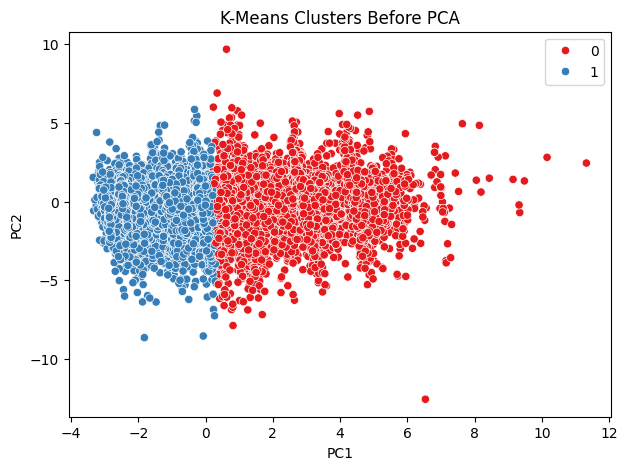

In [ ]:
# Visualize Clusters before PCA
plt.figure(figsize=(7, 5))

sns.scatterplot(
    x=X_pca["PC1"],
    y=X_pca["PC2"],
    hue=labels_before,
    palette="Set1"
)

plt.title("K-Means Clusters Before PCA")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()

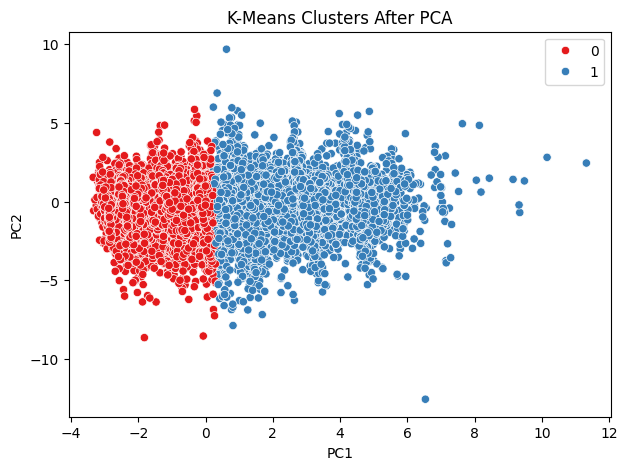

In [ ]:
#Clusters After PCA
plt.figure(figsize=(7, 5))
sns.scatterplot(
    x=X_pca["PC1"],
    y=X_pca["PC2"],
    hue=labels_after,
    palette="Set1"
)
plt.title("K-Means Clusters After PCA")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()

# Understand Each Cluster

In [ ]:

cluster_profile = (
    df_clean.groupby("cluster_before")
    [features + ["price"]]
    .median()
    .round(2)
)

display(cluster_profile)


,carat,depth,table,x,y,z,price
cluster_before,,,,,,,
0,1.11,61.9,58.0,6.66,6.65,4.10,6055.5
1,0.41,61.8,57.0,4.79,4.80,2.97,1053.0


## Trying different number of PCA component

In [ ]:
# Try different PCA components
for n in [2, 3, 4, 5, 6]:

    pca_test = PCA(n_components=n)
    X_test = pca_test.fit_transform(X_scaled)

    kmeans_test = KMeans(n_clusters=2,random_state=42,n_init=10)
    labels_test = kmeans_test.fit_predict(X_test)
    variance = pca_test.explained_variance_ratio_.sum()
    score = silhouette_score(X_test,labels_test,sample_size=3000,random_state=42)

    print(f"Components={n} | Variance={variance:.2%} | Silhouette={score:.3f}")


Components=2 | Variance=88.12% | Silhouette=0.487
Components=3 | Variance=99.46% | Silhouette=0.430
Components=4 | Variance=99.98% | Silhouette=0.429
Components=5 | Variance=99.99% | Silhouette=0.429
Components=6 | Variance=100.00% | Silhouette=0.429


# Comparing with DBSCAN

Here we apply DBSCAN on the same data before and after PCA, and compare it with the K-Means results. DBSCAN does not need the number of clusters, it groups points by density and labels the points that don't belong to any dense area as noise (-1)

## DBSCAN Before PCA

In [ ]:
from sklearn.cluster import DBSCAN

# Try different eps values before PCA
for eps in [0.3, 0.4, 0.5, 0.6, 0.7]:
    dbscan_test = DBSCAN(eps=eps, min_samples=10)
    labels_test = dbscan_test.fit_predict(X_scaled)

    n_clusters = len(set(labels_test)) - (1 if -1 in labels_test else 0)
    n_noise = list(labels_test).count(-1)
    score = silhouette_score(X_scaled, labels_test, sample_size=3000, random_state=42)

    print(f"eps={eps} | Clusters={n_clusters} | Noise={n_noise} | Silhouette={score:.3f}")

eps=0.3 | Clusters=30 | Noise=2781 | Silhouette=-0.174


eps=0.4 | Clusters=12 | Noise=1737 | Silhouette=-0.094


eps=0.5 | Clusters=2 | Noise=804 | Silhouette=0.485


eps=0.6 | Clusters=3 | Noise=475 | Silhouette=0.436


eps=0.7 | Clusters=2 | Noise=325 | Silhouette=0.459


Small eps gives a lot of noise and many small clusters, and big eps puts almost everything in one cluster.

eps=0.6 gives 3 clusters and less noise, but 2 of these clusters have only 10 diamonds each, so they are not real groups. We chose eps=0.5 because it has a higher silhouette score (0.485 vs 0.436) with low noise

In [ ]:
#train DBSCAN before pca
dbscan_before = DBSCAN(eps=0.5, min_samples=10)
db_labels_before = dbscan_before.fit_predict(X_scaled)

db_clusters_before = len(set(db_labels_before)) - (1 if -1 in db_labels_before else 0)
db_noise_before = list(db_labels_before).count(-1)
db_score_before = silhouette_score(X_scaled, db_labels_before, sample_size=3000, random_state=42)

print("Clusters:", db_clusters_before)
print("Noise points:", db_noise_before)
print("Silhouette Score Before PCA:", round(db_score_before, 3))

Clusters: 2
Noise points: 804
Silhouette Score Before PCA: 0.485


## DBSCAN After PCA

In [ ]:
# Try different eps values after PCA
for eps in [0.1, 0.2, 0.3, 0.4, 0.5]:
    dbscan_test = DBSCAN(eps=eps, min_samples=10)
    labels_test = dbscan_test.fit_predict(X_pca)

    n_clusters = len(set(labels_test)) - (1 if -1 in labels_test else 0)
    n_noise = list(labels_test).count(-1)
    score = silhouette_score(X_pca, labels_test, sample_size=3000, random_state=42)

    print(f"eps={eps} | Clusters={n_clusters} | Noise={n_noise} | Silhouette={score:.3f}")

eps=0.1 | Clusters=38 | Noise=2244 | Silhouette=-0.315


eps=0.2 | Clusters=7 | Noise=613 | Silhouette=0.332


eps=0.3 | Clusters=1 | Noise=311 | Silhouette=0.558


eps=0.4 | Clusters=1 | Noise=186 | Silhouette=0.594


eps=0.5 | Clusters=1 | Noise=117 | Silhouette=0.609


After PCA the points are closer to each other in 2D, so we need a smaller eps.

eps below 0.3 gives many tiny clusters. From eps=0.3 and up we always get 1 cluster, and the silhouette only goes up because the noise points become fewer. So we chose eps=0.3, the first value that gives a clean result

In [ ]:
#train DBSCAN after pca
dbscan_after = DBSCAN(eps=0.3, min_samples=10)
db_labels_after = dbscan_after.fit_predict(X_pca)

db_clusters_after = len(set(db_labels_after)) - (1 if -1 in db_labels_after else 0)
db_noise_after = list(db_labels_after).count(-1)
db_score_after = silhouette_score(X_pca, db_labels_after, sample_size=3000, random_state=42)

print("Clusters:", db_clusters_after)
print("Noise points:", db_noise_after)
print("Silhouette Score Before PCA:", round(db_score_before, 3))
print("Silhouette Score After PCA:", round(db_score_after, 3))

Clusters: 1
Noise points: 311
Silhouette Score Before PCA: 0.485
Silhouette Score After PCA: 0.558


## Visualization: DBSCAN Before vs After PCA

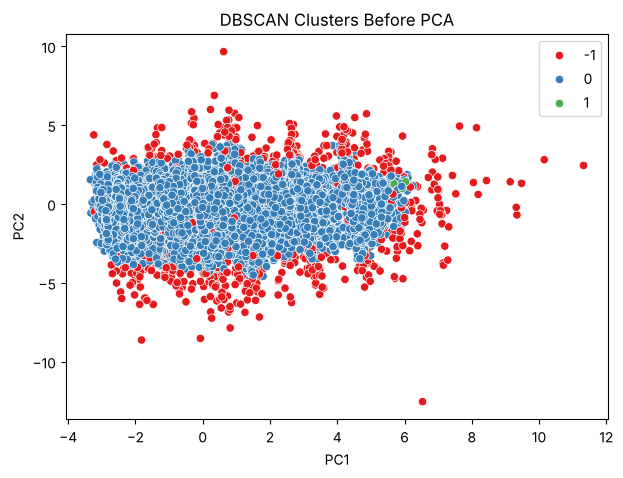

In [ ]:
# Visualize DBSCAN before PCA
plt.figure(figsize=(7, 5))

sns.scatterplot(
    x=X_pca["PC1"],
    y=X_pca["PC2"],
    hue=db_labels_before,
    palette="Set1"
)

plt.title("DBSCAN Clusters Before PCA")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()

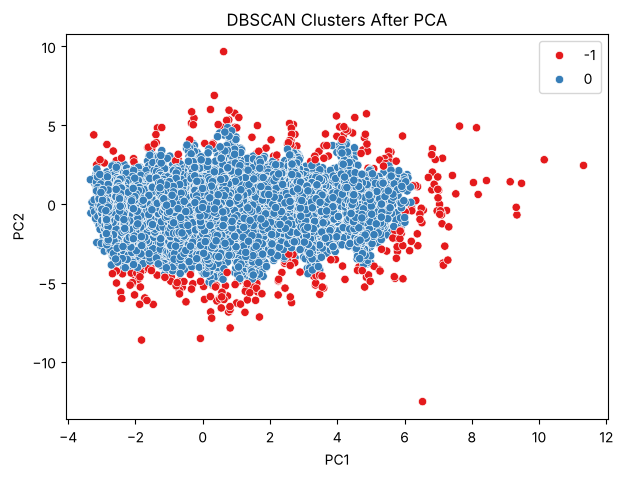

In [ ]:
# Visualize DBSCAN after PCA
plt.figure(figsize=(7, 5))

sns.scatterplot(
    x=X_pca["PC1"],
    y=X_pca["PC2"],
    hue=db_labels_after,
    palette="Set1"
)

plt.title("DBSCAN Clusters After PCA")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()

-1 in the legend means noise. In both plots most of the diamonds are in one big cluster and the noise points are on the edges

## Comparison: K-Means vs DBSCAN

In [ ]:
comparison = pd.DataFrame({
    "Algorithm": ["K-Means", "K-Means", "DBSCAN", "DBSCAN"],
    "Data": ["Before PCA", "After PCA", "Before PCA", "After PCA"],
    "Clusters": [2, 2, db_clusters_before, db_clusters_after],
    "Noise Points": [0, 0, db_noise_before, db_noise_after],
    "Silhouette": [score_before, score_after, db_score_before, db_score_after]
})

display(comparison.round(3))

,Algorithm,Data,Clusters,Noise Points,Silhouette
0,K-Means,Before PCA,2,0,0.429
1,K-Means,After PCA,2,0,0.487
2,DBSCAN,Before PCA,2,804,0.485
3,DBSCAN,After PCA,1,311,0.558


####Results:
- **K-Means**: Both approaches produced two groups mainly distinguished by diamond size. The Silhouette Score was 0.429 before PCA and 0.487 after PCA. The higher score describes separation in the reduced 2D space; since the scores use different feature spaces, it does not prove that PCA improved clustering overall.
- **DBSCAN**: Most diamonds were assigned to one large dense group, while some were labeled as noise. After PCA, DBSCAN identified one cluster and 311 noise points.
- **Comparing algorithms**: DBSCAN's Silhouette Score includes noise as a separate label in the calculation. Its higher score therefore does not mean it found more useful diamond groups than K-Means.
####Conclusion:
K-Means gave more interpretable size-based groups for this project. DBSCAN was more useful for highlighting unusual observations than for separating the diamonds into several meaningful groups.

# **Final Summary**

- **Data Preparation**

The original dataset contained 53,940 diamonds, with no missing values. We removed 47 records with invalid or inconsistent physical measurements, leaving 53,893 diamonds. Six physical features were standardized for clustering.

- **Did PCA Preserve the Important Information?**

PCA reduced the dataset from 6 physical features to 2 principal components, retaining 88.12% of the total variance. The remaining 11.88% was not captured by these two components, so some detail was lost.

- **What Changed in Clustering?**

K-Means identified two broad groups both before and after PCA. The Silhouette Score increased from 0.429 (original 6D space) to 0.487 (PCA 2D space). The clusters appear similarly separated in the 2D visualizations, but these scores are calculated in different feature spaces and cannot by themselves prove an improvement in clustering quality.

- **What Do the Diamond Groups Reveal?**

The original-feature clusters differed mainly by diamond size:
- Smaller diamonds: median 0.41 carats, median price $1,053.

- Larger diamonds: median 1.11 carats, median price $6,055.50.

Because price was not used to create the clusters, the difference in median prices is an interesting relationship observed afterward. It does not establish that size alone determines price, and this analysis does not measure differences in cut, color, or clarity.

- **What Did the DBSCAN Comparison Show?**

DBSCAN grouped most diamonds into one dense region and marked some as noise. After PCA, it detected one main cluster and 311 noise points. Although its Silhouette Score was higher, the score includes the noise label, so K-Means produced the more interpretable groups for our research question.

- **Final Takeaway**

PCA made diamond clustering easier to visualize while retaining most of the variance and the same broad size-based grouping. For this dataset, the main advantage of PCA was simplification and clearer visualization, rather than a proven improvement in clustering quality.